# Template Matching: Finding a Truck in a Photo

**Template matching** finds a small image, the **template**, inside a larger image. The template is slid over every position of the photo. At each position a similarity score is computed, and the position with the best score is the match. Template matching is the simplest way to find a known object, and it is part of the Phase 3 feature extraction step of this repository.

This notebook finds a delivery truck in a road photo:
1. Compares the matching methods that OpenCV provides.
2. Shows that a single best match is not enough: a threshold is needed to reject a non-match.
3. Removes duplicate detections with non-maximum suppression.
4. Searches at several scales, so that the truck is found at other sizes.
5. Saves all results to `output/`.

## 1. Imports

- `cv2` (OpenCV): image I/O, template matching and drawing
- `matplotlib`: displaying images
- `numpy`: array operations
- `pathlib`: file paths that work on any OS

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 80  # keeps the saved notebook small

## 2. How the score works

At each position the template is compared with the patch of the image underneath it. OpenCV offers several methods:

| Method | Score | Best value |
|---|---|---|
| `TM_SQDIFF` | sum of squared differences | **lowest** |
| `TM_CCOEFF_NORMED` | normalised cross-correlation, from -1 to 1 | **highest** |

`TM_CCOEFF_NORMED` subtracts the average brightness of the patch and divides by its contrast. A darker or brighter truck therefore still gets a high score. The `_NORMED` methods give scores that can be compared between images and templates.

## 3. Configuration

- `IMAGE_PATH`: the road photo. `TEMPLATE_PATH`: the truck from behind.
- `METHOD`: the matching method. The methods are compared in section 5.
- `THRESHOLD`: the minimum score for a detection. Below it, the match is treated as "no truck here". The truck scores 0.999, and the best positions without a truck score about 0.62 to 0.69, so 0.9 separates them.
- `IOU_LIMIT`: two detections that overlap by more than this fraction are duplicates of the same truck.
- `SCALES`: the sizes of the template that are tried, as factors of its original size.
- `SMALL_FACTOR`: the size of the shrunken photo used in section 8.
- All results are saved to `OUTPUT_DIR`.

In [2]:
IMAGE_PATH = Path("Find_Truck_color.jpg")
TEMPLATE_PATH = Path("Truck_template.jpg")
OUTPUT_DIR = Path("output")

METHOD = cv2.TM_CCOEFF_NORMED
THRESHOLD = 0.9
IOU_LIMIT = 0.3
SCALES = np.linspace(0.6, 1.4, 9)
SMALL_FACTOR = 0.7  # the photo is shrunk to imitate a truck further away

## 4. Load the images and helper functions

Helper functions:
- `load_image` wraps `cv2.imread`, which returns `None` on failure instead of raising an error. The template is loaded in grayscale.
- `show_images` shows several images side by side. Colour images are converted from BGR to RGB before display.
- `best_match` returns the best score and its position, taking into account whether the method is one where lower is better.
- `iou` measures how much two boxes overlap, as a fraction of their combined area.
- `detections` finds every position above the threshold, and removes duplicates by keeping the strongest score in each cluster.
- `draw_boxes` draws the boxes and their scores on a copy of the photo.
- `save_image` writes an image and checks the result.

In [3]:
def load_image(path: Path, flags: int = cv2.IMREAD_COLOR) -> np.ndarray:
    """Load an image with OpenCV and raise a clear error if it fails."""
    image = cv2.imread(str(path), flags)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path.resolve()}")
    return image


def show_images(images: dict[str, np.ndarray], cols: int | None = None, size: float = 5.0) -> None:
    """Show several images side by side. Colour images are converted from BGR to RGB for matplotlib."""
    cols = cols or len(images)
    rows = -(-len(images) // cols)  # ceiling division
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 0.75),
                             squeeze=False, layout="constrained")
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (title, img) in zip(axes.ravel(), images.items()):
        if img.ndim == 2:
            ax.imshow(img, cmap="gray")
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
    plt.show()


def best_match(result: np.ndarray, method: int) -> tuple[float, tuple[int, int]]:
    """Best score and its top-left corner. For TM_SQDIFF the best score is the lowest."""
    min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result)
    if method in (cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED):
        return min_val, min_loc
    return max_val, max_loc


def iou(a: tuple, b: tuple) -> float:
    """Intersection over union of two boxes (x1, y1, x2, y2)."""
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union


def detections(result: np.ndarray, tw: int, th: int, threshold: float) -> list[tuple]:
    """Boxes (x1, y1, x2, y2, score) for every peak above the threshold, duplicates removed."""
    ys, xs = np.where(result >= threshold)
    scores = result[ys, xs]
    kept: list[tuple] = []
    for i in np.argsort(-scores):  # strongest first
        box = (int(xs[i]), int(ys[i]), int(xs[i]) + tw, int(ys[i]) + th)
        if all(iou(box, k[:4]) <= IOU_LIMIT for k in kept):
            kept.append((*box, float(scores[i])))
    return kept


def draw_boxes(img: np.ndarray, boxes: list[tuple], colour=(0, 0, 255)) -> np.ndarray:
    """Copy of the photo with each box and its score drawn on it."""
    out = img.copy()
    for x1, y1, x2, y2, score in boxes:
        cv2.rectangle(out, (x1, y1), (x2, y2), colour, 4)
        cv2.putText(out, f"{score:.2f}", (x1, max(y1 - 8, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.9, colour, 2)
    return out


def save_image(path: Path, image: np.ndarray) -> None:
    """Save a BGR or single-channel image with OpenCV, raising an error if it fails."""
    path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(path), image):
        raise OSError(f"Could not write image: {path.resolve()}")
    print(f"Saved {path}")

Photo (height, width): (628, 1194); template (height, width): (209, 200)


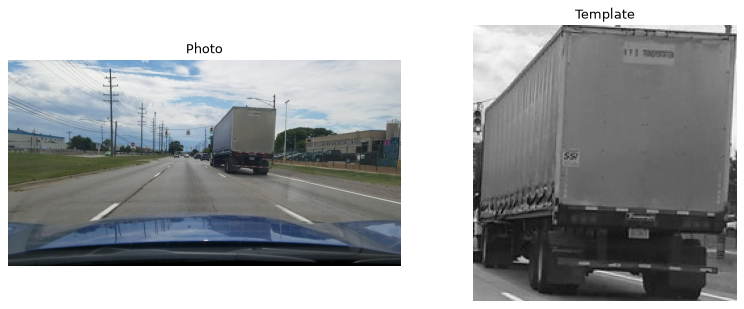

In [4]:
photo = load_image(IMAGE_PATH)
photo_gray = cv2.cvtColor(photo, cv2.COLOR_BGR2GRAY)
template = load_image(TEMPLATE_PATH, cv2.IMREAD_GRAYSCALE)
th, tw = template.shape

print(f"Photo (height, width): {photo_gray.shape}; template (height, width): {template.shape}")
show_images({"Photo": photo, "Template": template}, cols=2)

## 5. Compare the matching methods

The same template is matched with two methods. The heat map shows the score at every position: the bright spot is the best match. The best score and its position are printed.

TM_SQDIFF: best score 161856.000 at (616, 142)
TM_CCOEFF_NORMED: best score 0.999 at (616, 142)


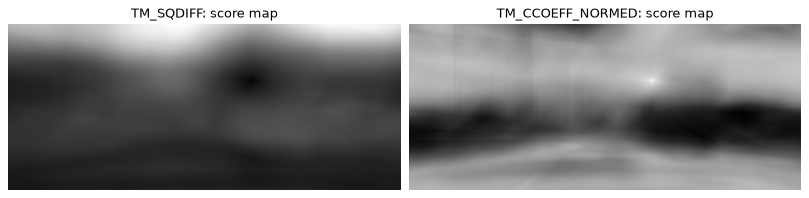

In [5]:
panels = {}
for name, method in {"TM_SQDIFF": cv2.TM_SQDIFF, "TM_CCOEFF_NORMED": cv2.TM_CCOEFF_NORMED}.items():
    result = cv2.matchTemplate(photo_gray, template, method)
    score, loc = best_match(result, method)
    print(f"{name}: best score {score:.3f} at {loc}")
    heat = cv2.normalize(result, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    panels[f"{name}: score map"] = heat
show_images(panels, cols=2)

## 6. A single best match is not enough

A simple version takes the best position and draws a box there, even if the truck is not in the photo. The next cell tests a part of the photo with no truck in it, the left-hand side of the road. The best match there still has a position and a score. The score shows that it is not a truck.

In [6]:
no_truck = photo_gray[:, :400]  # left-hand part of the photo, without the truck
result = cv2.matchTemplate(no_truck, template, METHOD)
score, loc = best_match(result, METHOD)
print(f"Left-hand part, no truck: best score {score:.3f} at {loc}")
print(f"Threshold: {THRESHOLD}; detected: {score >= THRESHOLD}")

Left-hand part, no truck: best score 0.620 at (97, 94)
Threshold: 0.9; detected: False


## 7. Find the truck with a threshold and duplicate removal

Every position with a score above `THRESHOLD` is a candidate. Neighbouring positions of the same truck all score high, so one truck gives many candidates. `detections` keeps the strongest candidate and drops every other one that overlaps it by more than `IOU_LIMIT`. This is called **non-maximum suppression**.

Detections at scale 1.0: 1
  box (616, 142, 816, 351), score 0.999


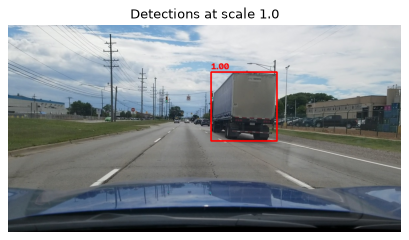

In [7]:
result = cv2.matchTemplate(photo_gray, template, METHOD)
boxes = detections(result, tw, th, THRESHOLD)
print(f"Detections at scale 1.0: {len(boxes)}")
for box in boxes:
    print(f"  box {box[:4]}, score {box[4]:.3f}")

show_images({"Detections at scale 1.0": draw_boxes(photo, boxes)})

## 8. Search at several scales

The truck in the photo may be larger or smaller than the template. The template is resized to each factor in `SCALES`, matched, and the detections from all sizes are combined. Non-maximum suppression runs again over the combined list, so a truck found at two sizes is reported once, with the strongest score.

Scales where the template is larger than the photo are skipped.

### 8.1 A truck further away

The photo is shrunk to `SMALL_FACTOR`, so the truck is smaller than the template. A single search at the template's size does not find it. The multi-scale search does.

In [8]:
small_photo = cv2.resize(photo_gray, None, fx=SMALL_FACTOR, fy=SMALL_FACTOR, interpolation=cv2.INTER_AREA)

single = cv2.matchTemplate(small_photo, template, METHOD)
single_score, single_loc = best_match(single, METHOD)
print(f"Shrunk photo, one scale: best score {single_score:.3f} at {single_loc}, detected: {single_score >= THRESHOLD}")

Shrunk photo, one scale: best score 0.649 at (391, 41), detected: False


### 8.2 Search all scales and combine the detections

The template is resized to each factor in `SCALES`, matched, and the detections from all sizes are combined. Non-maximum suppression runs again over the combined list, so a truck found at two sizes is reported once, with the strongest score. Scales where the template is larger than the photo are skipped.

Candidates over all scales: 1; after removing duplicates: 1
  box (431, 99, 571, 245), score 0.989, scale 0.70


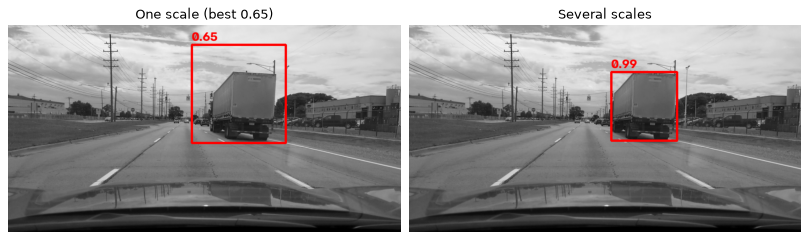

In [9]:
all_boxes: list[tuple] = []
for scale in SCALES:
    scaled = cv2.resize(template, None, fx=scale, fy=scale,
                        interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR)
    sh, sw = scaled.shape
    if sh >= small_photo.shape[0] or sw >= small_photo.shape[1]:
        continue
    result = cv2.matchTemplate(small_photo, scaled, METHOD)
    all_boxes += [(*b[:4], b[4], scale) for b in detections(result, sw, sh, THRESHOLD)]

all_boxes.sort(key=lambda b: -b[4])
final: list[tuple] = []
for box in all_boxes:
    if all(iou(box[:4], k[:4]) <= IOU_LIMIT for k in final):
        final.append(box)

print(f"Candidates over all scales: {len(all_boxes)}; after removing duplicates: {len(final)}")
for box in final:
    print(f"  box {box[:4]}, score {box[4]:.3f}, scale {box[5]:.2f}")

show_images({
    f"One scale (best {single_score:.2f})": draw_boxes(cv2.cvtColor(small_photo, cv2.COLOR_GRAY2BGR),
                                                       [(*single_loc, single_loc[0] + tw, single_loc[1] + th, single_score)]),
    "Several scales": draw_boxes(cv2.cvtColor(small_photo, cv2.COLOR_GRAY2BGR), [b[:5] for b in final]),
}, cols=2)

## 9. Save the results

All results are written to `OUTPUT_DIR`, using the input file name as a prefix.

In [10]:
stem = IMAGE_PATH.stem
outputs = {
    "photo_gray": photo_gray,
    "truck_found": draw_boxes(photo, boxes),
    "shrunk_truck_found": draw_boxes(cv2.cvtColor(small_photo, cv2.COLOR_GRAY2BGR), [b[:5] for b in final]),
}
for suffix, result_img in outputs.items():
    save_image(OUTPUT_DIR / f"{stem}_{suffix}.jpg", result_img)

Saved output/Find_Truck_color_photo_gray.jpg
Saved output/Find_Truck_color_truck_found.jpg
Saved output/Find_Truck_color_shrunk_truck_found.jpg


## 10. Conclusion

- **Template matching** slides a template over the image and scores every position. `TM_CCOEFF_NORMED` is robust to changes in brightness and contrast, and its best value is the highest.
- The best score is not a detection on its own. A **threshold** rejects matches where the object is not present.
- Neighbouring positions give many candidates for one object. **Non-maximum suppression** keeps the strongest one.
- Searching over several **scales** finds objects that are larger or smaller than the template.

**Limits of this method**
- It needs an almost identical appearance. A truck from the side, in a different colour, or partly hidden will not match. Rotation and perspective change the appearance too.
- It needs one template for each appearance, and it is slow for large images and many scales.

**Current standards beyond this notebook**
- **Feature matching:** keypoint detectors and descriptors such as SIFT or ORB find points that survive changes in scale, rotation and lighting. A homography with RANSAC then checks the geometry. This works for a known object seen from a different angle.
- **Learned detectors:** neural networks such as YOLO or Faster R-CNN detect object classes, for example trucks, from many labelled examples, without a template. They are the standard for vehicle detection on road images.